In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

chec the pytorch loss function

In [2]:
nn.NLLLoss

torch.nn.modules.loss.NLLLoss

# Create and test cutom loss functions

In [3]:
# general form for a loss function
class myLoss_L1(nn.Module):
  def __init__(self):
    super().__init__()

  def forward(self, y_hat, y):

    # L1 loss
    l = torch.mean(torch.abs(y_hat - y))

    # correlation error (just as an example possibilities)
    # l = 1 - torch.corrcoef((y_hat, y))

    return l

class myLoss_L2(nn.Module):
  def __init__(self):
    super().__init__()

  def forward(self, y_hat, y):

    # mean-squered error
    l = torch.mean((y_hat - y)**2)

    return l

In [4]:
# create instances of the loss classes
loss_fn_1 = myLoss_L1()
loss_fn_2 = myLoss_L2()

# test value = torch.tensor(2.)
predicted_value = torch.tensor(2.)
target_value = 5

# report
print(f'Model output = {predicted_value}')
print(f'Target value = {target_value}\n')
print(f'L1 loss: {loss_fn_1(predicted_value, target_value)}')
print(f'L2 loss: {loss_fn_2(predicted_value, target_value)}')

Model output = 2.0
Target value = 5

L1 loss: 3.0
L2 loss: 9.0


Demonstrate in a simple example

In [5]:
# initialize weight values
w1 = torch.tensor([2.], requires_grad=True)
w2 = torch.tensor([2.], requires_grad=True)

# target value
target = torch.tensor([3.])

# create the optimizers
learning_rate = 0.05
optimizer_1 = torch.optim.SGD([w1], lr=learning_rate)
optimizer_2 = torch.optim.SGD([w2], lr=learning_rate)

# number of stored points
num_iters = 50

# initialize results matrices
all_losses = np.zeros((2, num_iters))
all_weights = np.zeros((2, num_iters))

# store initial values
all_weights[0, 0] = w1.item()
all_weights[1, 0] = w2.item()

all_losses[0, 0] = loss_fn_1(w1, target).item()
all_losses[1, 0] = loss_fn_2(w2, target).item()

# training loop
for i in range(1, num_iters):

    # train w1
    optimizer_1.zero_grad()
    loss_1 = loss_fn_1(w1, target)
    loss_1.backward()
    optimizer_1.step()

    # train w2
    optimizer_2.zero_grad()
    loss_2 = loss_fn_2(w2, target)
    loss_2.backward()
    optimizer_2.step()

    # store updated weights
    all_weights[0, i] = w1.item()
    all_weights[1, i] = w2.item()

    # store losses after update
    all_losses[0, i] = loss_fn_1(w1, target).item()
    all_losses[1, i] = loss_fn_2(w2, target).item()

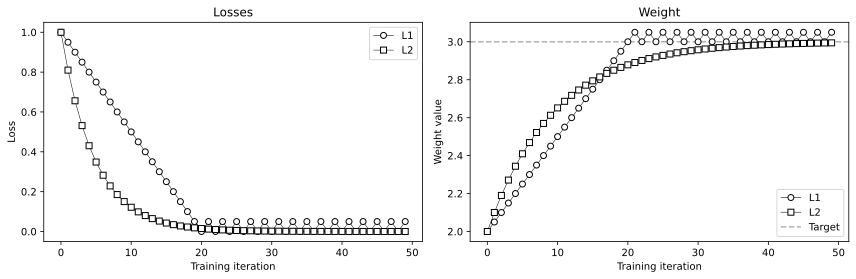

In [6]:
_, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].plot(range(num_iters), all_losses[0], 'ko-', linewidth=.5, markerfacecolor='w', label='L1')
axs[0].plot(range(num_iters), all_losses[1], 'ks-', linewidth=.5, markerfacecolor='w', label='L2')
axs[0].set(title='Losses', ylabel='Loss', xlabel='Training iteration')
axs[0].legend()

axs[1].plot(range(num_iters), all_weights[0], 'ko-', linewidth=.5, markerfacecolor='w', label='L1')
axs[1].plot(range(num_iters), all_weights[1], 'ks-', linewidth=.5, markerfacecolor='w', label='L2')
axs[1].axhline(target.item(), linestyle='--', color=[.7, .7, .7], zorder=-10, label='Target')
axs[1].set(title='Weight', ylabel='Weight value', xlabel='Training iteration')
axs[1].legend()

plt.tight_layout()
plt.show()